# Ranking & monetisation (modeled)

**Block I — modeled.** This notebook answers one question: *how do ranking policy and partner mix move metasearch revenue?* It is the "modeled" half of the lab.

> **Caveat — read first.** Every number here comes from `serp_offers`, a **synthetic** offer log. The offers, prices, clicks and commissions were generated by a documented simulator (`src/serp_sim.py`), seeded on *real* `user_id` values but **not observed** in the market. Conclusions are about **method** — how a ranking/metric pipeline behaves — **not** about the real flight-search market. This block is never fused with the measured feeds (see `docs/adr/0001-modeled-vs-measured.md`).

Evidence class for this entire notebook: **modeled**.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display, Markdown

PROJECT_ROOT = Path("..").resolve()
PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"

ranking = json.loads((REPORTS / "ranking_eval.json").read_text(encoding="utf-8"))
offers = pd.read_parquet(PROCESSED / "serp_offers.parquet")
funnel_pos = pd.read_parquet(PROCESSED / "funnel_by_position.parquet")
revenue_pos = pd.read_parquet(PROCESSED / "revenue_by_position.parquet")
partner_q = pd.read_parquet(PROCESSED / "partner_quality.parquet")

print(
    f"offers={len(offers):,}  searches={offers['search_id'].nunique():,}  "
    f"partners={offers['partner'].nunique()}  positions={int(offers['position'].max())}"
)
print("evidence class: MODELED (serp_offers is synthetic)")

offers=120,136  searches=12,000  partners=8  positions=15
evidence class: MODELED (serp_offers is synthetic)


## 2. Position bias — users examine the top of the SERP far more

Position bias is the modeled tendency to examine top slots more than lower ones: here `examine_prob` follows the decaying curve `(1/k)^eta`. The simulator uses `eta_mobile = 1.3` (steeper decay on mobile) and `eta_desktop = 1.0` (`ranking_eval.json`). Because of this bias, the **naive** click rate badly understates true click propensity — the gap below is **3.86x** (0.163 vs 0.629), so any ranker compared on raw CTR is compared on a biased number.

examine_prob by position (modeled), mobile vs desktop


device,desktop,mobile
position,,
1,1.0000,1.0000
2,0.5000,0.4061
3,0.3333,0.2397
4,0.2500,0.1649
5,0.2000,0.1234
6,0.1667,0.0974
7,0.1429,0.0797
8,0.1250,0.0670
9,0.1111,0.0575



model eta (ranking_eval.json): mobile=1.30  desktop=1.00
naive ctr          = 0.1630
position-free ctr  = 0.6287
IPW (known curve)  = 0.6253
IPW (EM-estimated) = 0.6288


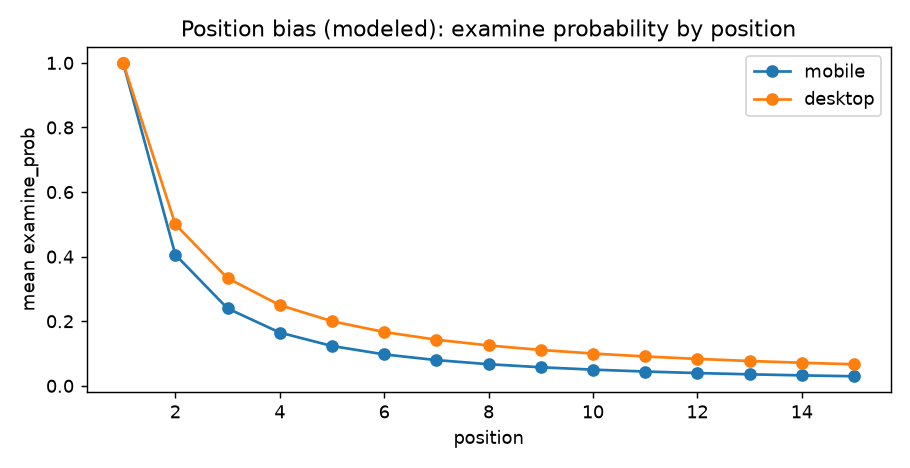

In [2]:
bias = offers.groupby(["device", "position"])["examine_prob"].mean().unstack(0).round(4)
bias.index.name = "position"
print("examine_prob by position (modeled), mobile vs desktop")
display(bias.head(10))

print("\nmodel eta (ranking_eval.json): mobile=%.2f  desktop=%.2f" % (
    ranking["ctr"]["eta_mobile"], ranking["ctr"]["eta_desktop"]))
print("naive ctr          = %.4f" % ranking["ctr"]["naive"])
print("position-free ctr  = %.4f" % ranking["ctr"]["true_position_free"])
print("IPW (known curve)  = %.4f" % ranking["ctr"]["ipw_known_curve"])
print("IPW (EM-estimated) = %.4f" % ranking["ctr"]["ipw_em_estimated"])

display(Image(filename=str(FIGURES / "position_bias.png")))

## 3. Funnel by position and revenue decay

The view `funnel_by_position` (`sql/03_funnel.sql`) materialises the impression -> click -> redirect -> book chain per slot. `revenue_per_search` / `revenue_by_position` (`sql/04_revenue_per_search.sql`) then turn the same log into money. Revenue decays steeply with rank: **position 1 alone collects ~47% of all modeled SERP revenue**.

**Funnel by position (`funnel_by_position` view, modeled)**

,position,impressions,offers,clicks,redirects,bookings,booked_commission,avg_price,ctr,click_to_redirect,redirect_to_book,impression_to_book,cumulative_click_share
0,1,12000,12000,8219,4428,1811,6.959537e+06,53789.164900,0.684917,0.538752,0.408988,0.150917,0.068414
1,2,12000,12000,3534,1919,757,2.934609e+06,53709.462489,0.294500,0.543011,0.394476,0.063083,0.097831
2,3,12000,12000,2072,1139,486,1.776834e+06,53991.119741,0.172667,0.549710,0.426690,0.040500,0.115078
3,4,12000,12000,1504,794,287,9.561266e+05,54210.543571,0.125333,0.527926,0.361461,0.023917,0.127597
4,5,12000,12000,1178,632,235,8.335301e+05,54491.869204,0.098167,0.536503,0.371835,0.019583,0.137403
5,6,10918,10918,840,419,156,4.164377e+05,54751.411103,0.076937,0.498810,0.372315,0.014288,0.144395
6,7,9807,9807,600,340,124,3.132394e+05,54728.443453,0.061181,0.566667,0.364706,0.012644,0.149389
7,8,8762,8762,474,234,81,1.656326e+05,54723.512421,0.054097,0.493671,0.346154,0.009244,0.153335
8,9,7674,7674,338,169,61,1.241955e+05,54849.365611,0.044045,0.500000,0.360947,0.007949,0.156148
9,10,6580,6580,278,152,53,8.387047e+04,54974.270018,0.042249,0.546763,0.348684,0.008055,0.158462


**Revenue decay by position (`revenue_by_position` view, modeled)**

,position,clicks,bookings,revenue_per_offer,revenue_per_impression,cumulative_revenue_share
0,1,8219,1811,580.293,580.293,0.473
1,2,3534,757,244.847,244.847,0.673
2,3,2072,486,148.549,148.549,0.794
3,4,1504,287,80.282,80.282,0.860
4,5,1178,235,70.276,70.276,0.917
5,6,840,156,39.019,39.019,0.946
6,7,600,124,32.892,32.892,0.968
7,8,474,81,19.871,19.871,0.980
8,9,338,61,17.147,17.147,0.989
9,10,278,53,13.697,13.697,0.995


top-1 position captures 47.3% of modeled SERP revenue


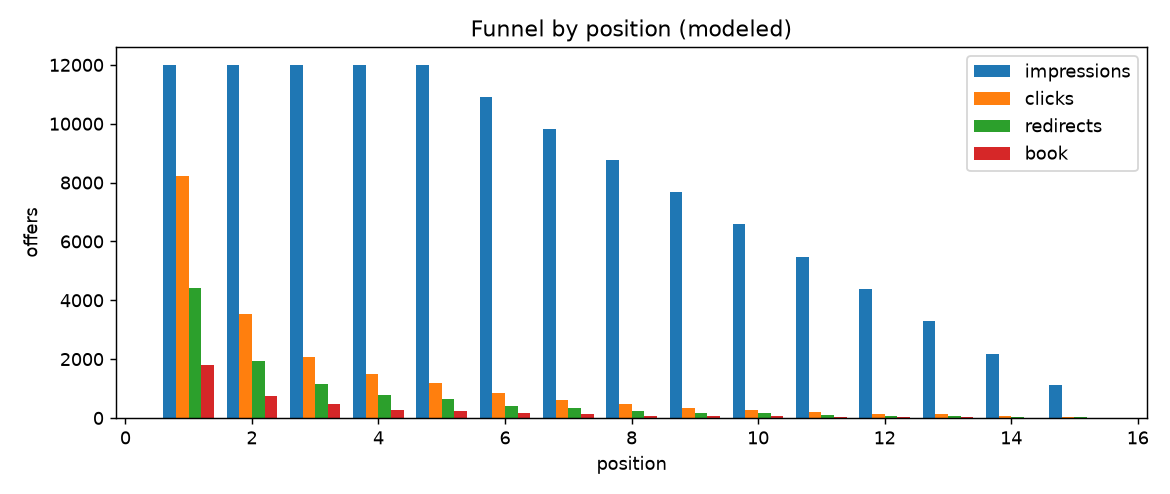

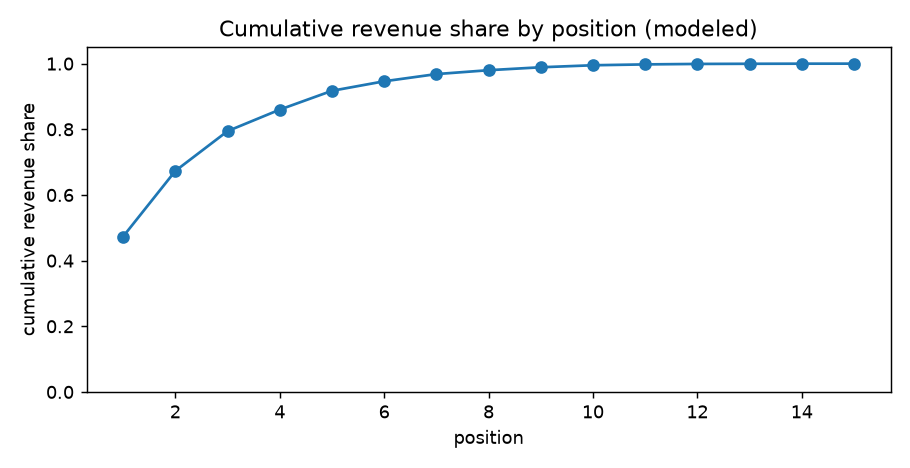

In [3]:
display(Markdown("**Funnel by position (`funnel_by_position` view, modeled)**"))
display(funnel_pos.head(10))

display(Markdown("**Revenue decay by position (`revenue_by_position` view, modeled)**"))
display(revenue_pos[["position", "clicks", "bookings", "revenue_per_offer",
                     "revenue_per_impression", "cumulative_revenue_share"]].head(10).round(3))

print(f"top-1 position captures {revenue_pos['cumulative_revenue_share'].iloc[0]:.1%} of modeled SERP revenue")

display(Image(filename=str(FIGURES / "funnel_by_position.png")))
display(Image(filename=str(FIGURES / "cumulative_revenue_share.png")))

## 4. Partner quality — CTR x commission quadrant

`partner_quality` (`sql/03_funnel.sql`) ranks each partner by realised revenue per slot it occupied (`monetisation_rank`). Two economic types coexist: **CPA** partners pay commission only on a booking, **CPC** partners pay a fee on the click. A partner can post a high CTR and still rank low on money if its commission per offer is small — the quadrant separates "cheap clicks" from "valuable bookings".

,partner,avg_position,ctr,booking_rate,commission_per_offer,commission_per_search,monetisation_rank
0,SkyTour,2.7500,0.3763,0.0879,338.7670,862.5524,1
1,OTA Global,4.0822,0.2884,0.0737,199.7370,511.7061,2
2,AviaCenter,3.9921,0.2204,0.0411,191.5589,489.7687,3
3,FlyDirect,4.8054,0.1508,0.0258,156.0273,396.0139,4
4,TripMasters,6.1521,0.0738,0.0113,87.2304,227.2041,5
5,MetaFly,8.7809,0.0617,0.0129,0.4915,1.2457,6
6,GoFare,9.5625,0.0492,0.0076,0.4418,1.1355,7
7,CloudTrip,7.9078,0.0842,0.0173,0.3797,0.9740,8


partner_type split (modeled): {'CPA': 75168, 'CPC': 44968}


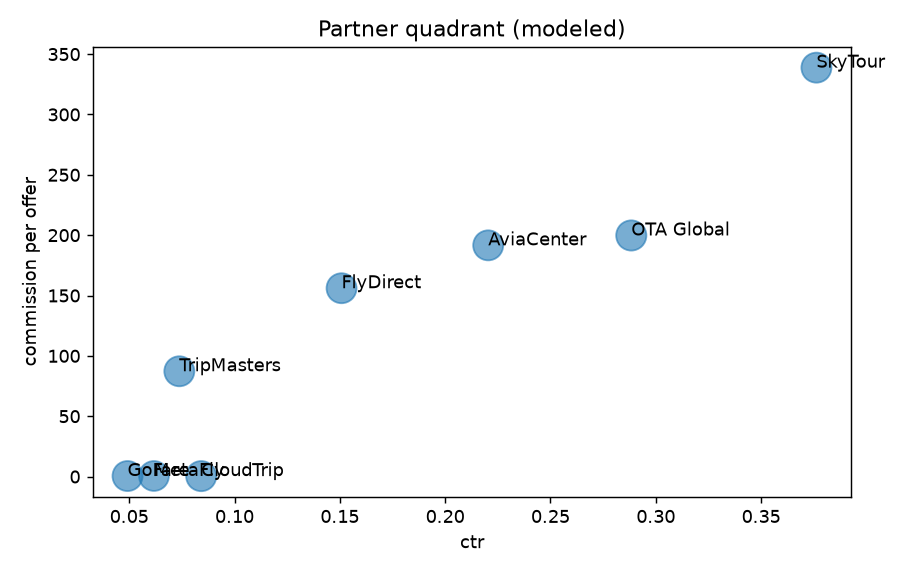

In [4]:
display(partner_q[["partner", "avg_position", "ctr", "booking_rate",
                   "commission_per_offer", "commission_per_search",
                   "monetisation_rank"]].round(4))

print("partner_type split (modeled):", offers["partner_type"].value_counts().to_dict())

display(Image(filename=str(FIGURES / "partner_quadrant.png")))

## 5. Policy divergence — the headline: better offline is not better online

`ranking_eval.json` scores **seven** ship-able and reference policies, plus one `delta_relevance_minus_revenue` row that is a **difference, not a policy** (it has no NDCG of its own; the plot filters it out). Two pairs matter:

1. **Reference oracles** (`relevance`, `revenue`) read the simulator's ground truth. Here NDCG falls 1.000 → 0.932 while revenue rises 868.9 → 1,196.6 ₽/search: the `ndcg_rises_while_revenue_falls = True` flag. This pair is `modeled` — it describes the objective, not a shippable ranker.
2. **The feasible pair** (`ctr_objective`, `revenue_objective`) shares one feature matrix, one `beta` and one greedy slot mechanism; only the utility differs. It is the pair the headline uses: **+284.74 ₽/search (+34.45%)** for **−16.84% CTR**. The exchange rate is 981.83 ₽ per forgone click. The interesting part is that the learned ranker (`propensity_logistic`, 826.56 ₽) **loses to plain price sorting** (`price_asc`, 843.91 ₽).

MRR is reported for every policy now: 0.960 for `production`, 0.994 for `ctr_objective`, 0.686 for `revenue_objective`. The money objective is the only one that ranks *worse* on both offline metrics — which is exactly why offline metrics cannot be the release gate.

,policy,ndcg_at_k,mrr,revenue_per_search,clicks_per_search
0,relevance,1.0000,1.0000,868.8691,1.7602
1,revenue,0.9316,0.9758,1196.5930,1.5920
2,production,0.9480,0.9602,1175.7956,1.6344
3,price_asc,0.9850,0.9937,843.9123,1.7228
4,click_trained,0.9823,0.9969,692.9776,1.7128
5,propensity_logistic,0.9850,0.9944,826.5601,1.7225
6,ctr_objective,0.9850,0.9944,826.5601,1.7225
7,revenue_objective,0.8827,0.6861,1111.2960,1.4325


oracles: NDCG@10 relevance=1.000  revenue=0.932
oracles: revenue/search relevance=868.9  revenue=1196.6
ndcg_rises_while_revenue_falls = True
feasible pair: revenue/search 826.56 -> 1111.30  (+34.45%)
feasible pair: CTR delta -16.84%, breakeven 981.83 RUB per forgone click
failed hypothesis: learned 826.56 vs price_asc 843.91


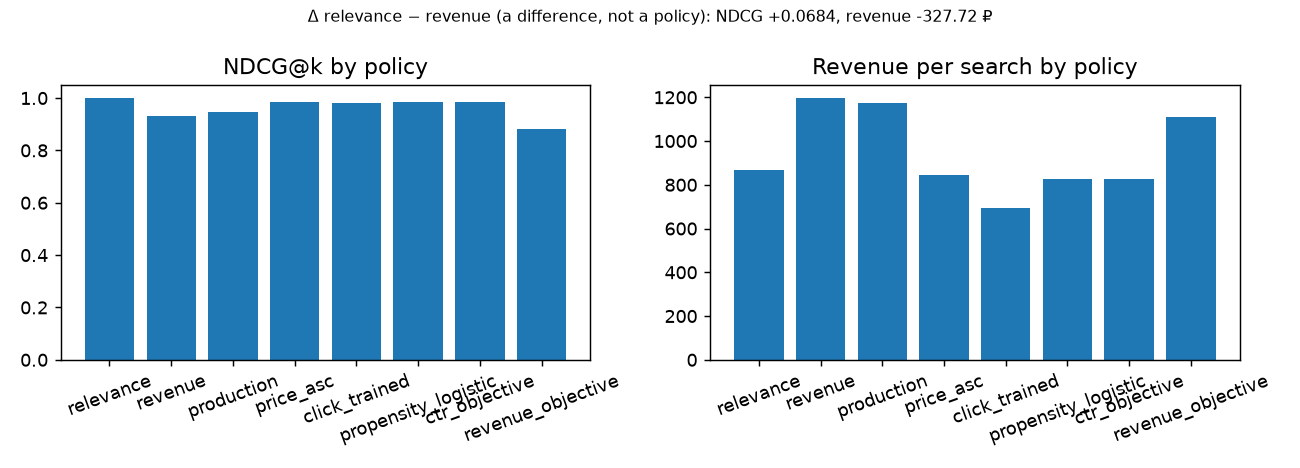

In [5]:
policies = pd.DataFrame(ranking["policies"])
real = policies[~policies["policy"].str.startswith("delta")]
display(real[["policy", "ndcg_at_k", "mrr", "revenue_per_search", "clicks_per_search"]].round(4))

d = ranking["divergence"]
print(f"oracles: NDCG@10 relevance={d['ndcg_relevance']:.3f}  revenue={d['ndcg_revenue']:.3f}")
print(f"oracles: revenue/search relevance={d['revenue_per_search_relevance']:.1f}  revenue={d['revenue_per_search_revenue']:.1f}")
print(f"ndcg_rises_while_revenue_falls = {d['ndcg_rises_while_revenue_falls']}")

hl = ranking["headline"]["headline"]
print(
    f"feasible pair: revenue/search {ranking['headline']['policies']['ctr_objective']['revenue_per_search']:.2f}"
    f" -> {ranking['headline']['policies']['revenue_objective']['revenue_per_search']:.2f}"
    f"  ({hl['revenue_per_search_delta_rel']:+.2%})"
)
print(
    f"feasible pair: CTR delta {hl['ctr_delta_rel']:+.2%}, "
    f"breakeven {abs(hl['breakeven_rub_per_forgone_click']):.2f} RUB per forgone click"
)
fh = ranking["headline"]["failed_hypothesis"]
print(f"failed hypothesis: learned {fh['learned_ranker']:.2f} vs price_asc {fh['price_asc']:.2f}")

display(Image(filename=str(FIGURES / "ranking_divergence.png")))

## 6. Business conclusion

**Modeled — this is method, not market.** What a metasearch analyst should take away:

- **Ranking on money is not free.** On the same information set, the revenue objective buys **+284.74 ₽ per search (+34.45%)** and pays **−16.84% of clicks**. That is an exchange rate of **981.83 ₽ per forgone click** — a price, not a verdict, because the value of a click (LTV, brand) is not in the data.
- **Do not ship this ranker.** On the rollout the money objective loses **−14.26% revenue** (−174.20 ₽/search) and breaks two guardrails: CTR −13.06% (p = 7e-6) and booking conversion −16.05% (p = 0.009). Verdict `do_not_ship`.
- **The bottleneck is the signal, not the objective.** The shipped order is a blend of the simulator's ground-truth relevance and expected revenue (`src/serp_sim.py:457-458`); the learned policies see three observable columns. Evidence: `ctr_objective` = `propensity_logistic` = 826.56 ₽, and plain `price_asc` (843.91 ₽) beats the learned ranker.
- **No single offline metric can be the release gate.** `revenue_objective` is the worst policy on both NDCG (0.883) and MRR (0.686) yet the best on money; ranking by NDCG alone would reject it, and ranking by money alone would ship a CTR collapse. The gate has to be a guardrail set on the live readout.
- **Defend the top slots.** Position 1 collects 47.3% of modeled SERP revenue; the top-5 partners carry 99.3% of commission, so the slots worth pricing are the ones at the top.

Caveat restated: all of the above is **modeled** on `serp_offers` (`docs/adr/0001-modeled-vs-measured.md`). The numbers demonstrate the method; they do not describe the real market.